<a href="https://colab.research.google.com/github/JuanEsteban-prog/AprendizajeAutom-ticoInicial/blob/main/Tareas/19Nov/04_Agrupamiento_kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/04-Agrupamiento-kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento k-Means
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento k-Means al conjunto de datos seleccionado en las primeras semanas.

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# Configuración visual general
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)


---
## <font color='264CC7'> Preprocesamiento de datos </font>

Usa el mismo conjunto de datos que seleccionaste en las primeras semanas y empleaste en el ejercicio de agrupamiento jerárquico. El conjunto Pokémon del notebook de clase es solo un ejemplo. En Colab, carga tu archivo desde una fuente accesible o súbelo a la sesión y documenta cómo repetir la carga.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Trata los faltantes y escala las variables numéricas cuando sus escalas sean diferentes; excluye identificadores y etiquetas de la matriz de agrupamiento.</li>
</ul>
</div>

In [2]:
# Carga del conjunto de datos Wine (UCI Machine Learning Repository)
# Cómo repetir la carga en Google Colab:
# Este conjunto de datos viene integrado en scikit-learn (`load_wine`), por lo que
# se carga directamente sin necesidad de subir archivos manuales ni depender de enlaces externos.
wine = load_wine(as_frame=True)
df = wine.frame.copy()

# Agregamos un identificador único por muestra para facilitar la inspección de integrantes
df.insert(0, "id_vino", [f"Vino_{i+1:03d}" for i in range(len(df))])

print(f"Dimensiones del conjunto de datos: {df.shape[0]} filas y {df.shape[1]} columnas")
print("\nPrimeras 5 filas del conjunto de datos:")
print(df.head().to_string(index=False))

# Variables numéricas para el agrupamiento (excluimos el identificador 'id_vino' y la etiqueta 'target')
columnas_numericas = list(wine.feature_names)

print("\nDescripción estadística de las variables numéricas (escala original):")
print(df[columnas_numericas].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

# Verificación y tratamiento de valores faltantes
faltantes = df[columnas_numericas].isna().sum()
print(f"\nTotal de valores faltantes en las variables numéricas: {faltantes.sum()}")

# Aplicamos imputación por mediana como paso reproducible de limpieza (en caso de existir faltantes)
imputer = SimpleImputer(strategy="median")
X_imputado = imputer.fit_transform(df[columnas_numericas])

# Escalamiento estándar (media = 0, desviación estándar = 1)
# Es necesario porque las escalas difieren drásticamente (ej. proline hasta 1680 vs nonflavanoid_phenols < 0.7)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputado)
X_scaled_df = pd.DataFrame(X_scaled, columns=columnas_numericas)

print("\nPrimeras 5 filas de la matriz preparada (estandarizada):")
print(X_scaled_df.head().round(3).to_string(index=False))


Dimensiones del conjunto de datos: 178 filas y 15 columnas

Primeras 5 filas del conjunto de datos:
 id_vino  alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  od280/od315_of_diluted_wines  proline  target
Vino_001    14.23        1.71 2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64 1.04                          3.92   1065.0       0
Vino_002    13.20        1.78 2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38 1.05                          3.40   1050.0       0
Vino_003    13.16        2.36 2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68 1.03                          3.17   1185.0       0
Vino_004    14.37        1.95 2.50               16.8      113.0           3.85        3.49         

---
## <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Propón un número de clústeres para k-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica de inercia para valores de k entre 1 y 10, sin superar el número de observaciones disponibles.</li>
  <li>Identifica si aparece un codo claro; si no aparece, explica cómo elegirías un valor razonable.</li>
  <li>Justifica tu elección y explica por qué la inercia, por sí sola, no determina la calidad de los grupos.</li>
</ul>
</div>


 k  Inercia  Reducción absoluta  Reducción (%)
 1  2314.00                 NaN            NaN
 2  1658.76              655.24          28.32
 3  1277.93              380.83          22.96
 4  1175.43              102.50           8.02
 5  1109.51               65.92           5.61
 6  1046.00               63.51           5.72
 7   981.60               64.40           6.16
 8   935.20               46.40           4.73
 9   889.89               45.31           4.84
10   845.90               43.99           4.94


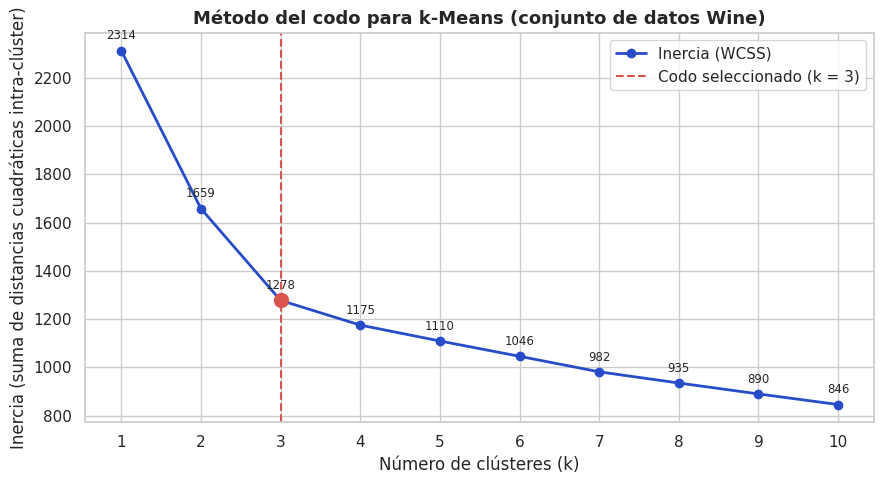

In [3]:
# Método del codo para valores de k entre 1 y 10 (sin superar el número de observaciones)
max_k = min(10, len(X_scaled))
rango_k = range(1, max_k + 1)
inercias = []

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

# Tabla resumen de inercia y reducción marginal
tabla_codo = pd.DataFrame({
    "k": list(rango_k),
    "Inercia": np.round(inercias, 2)
})
tabla_codo["Reducción absoluta"] = tabla_codo["Inercia"].shift(1) - tabla_codo["Inercia"]
tabla_codo["Reducción (%)"] = (tabla_codo["Reducción absoluta"] / tabla_codo["Inercia"].shift(1) * 100).round(2)
print(tabla_codo.to_string(index=False))

# Gráfica del método del codo
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(rango_k), inercias, marker="o", linewidth=2, color="#264CC7", label="Inercia (WCSS)")
ax.axvline(x=3, color="#D9534F", linestyle="--", linewidth=1.5, label="Codo seleccionado (k = 3)")
ax.scatter([3], [inercias[2]], color="#D9534F", s=100, zorder=5)

for k_val, iner in zip(rango_k, inercias):
    ax.annotate(f"{iner:.0f}", (k_val, iner), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5)

ax.set_title("Método del codo para k-Means (conjunto de datos Wine)", fontsize=13, fontweight="bold")
ax.set_xlabel("Número de clústeres (k)")
ax.set_ylabel("Inercia (suma de distancias cuadráticas intra-clúster)")
ax.set_xticks(list(rango_k))
ax.legend()
plt.tight_layout()
plt.show()


### Análisis del método del codo y justificación

* **Identificación del codo:** Sí aparece un codo claro en k = 3.
* **Qué hacer si no apareciera un codo claro:** Cuando la curva desciende suavemente sin un quiebre evidente, no conviene decidir solo de forma visual. En ese escenario se debe combinar el método del codo con métricas internas complementarias (como el coeficiente de silueta, el índice de Calinski-Harabasz o Davies-Bouldin), verificar la estabilidad de las particiones ante distintas semillas aleatorias y priorizar un valor de k que produzca grupos interpretables y útiles para el problema.
* **Justificación de $k = 3$ y por qué la inercia por sí sola no determina la calidad:** Se eligió k = 3 porque captura el mayor ahorro relativo de dispersión interna sin fragmentar artificialmente los datos. La inercia por sí sola no garantiza buenos grupos.


---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [4]:
# Entrenamiento de k-Means con k = 3 sobre la matriz preparada
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# Tamaño de cada grupo
print("Cantidad de observaciones por grupo:")
print(df["cluster"].value_counts().sort_index().rename_axis("Cluster").to_frame("Cantidad"))

# Media de cada grupo (en escala original para facilitar la interpretación)
print("\nMedia de cada variable por grupo:")
medias = df.groupby("cluster")[columnas_numericas].mean().round(2)
print(medias)

# Mínimo de cada grupo
print("\nMínimo de cada variable por grupo:")
minimos = df.groupby("cluster")[columnas_numericas].min().round(2)
print(minimos)

# Máximo de cada grupo
print("\nMáximo de cada variable por grupo:")
maximos = df.groupby("cluster")[columnas_numericas].max().round(2)
print(maximos)

# Algunos integrantes representativos de cada grupo
cols_muestra = ["id_vino", "alcohol", "malic_acid", "flavanoids", "color_intensity", "hue", "proline"]
print("\nEjemplos de integrantes de cada grupo:")
for c in sorted(df["cluster"].unique()):
    print(f"\n--- Grupo {c} (total: {(df['cluster'] == c).sum()} vinos) ---")
    print(df[df["cluster"] == c][cols_muestra].head(5).to_string(index=False))


Cantidad de observaciones por grupo:
         Cantidad
Cluster          
0              65
1              51
2              62

Media de cada variable por grupo:
         alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline
cluster                                                                                                                                                                                         
0          12.25        1.90  2.23              20.06      92.74           2.25        2.05                  0.36             1.62             2.97  1.06                          2.80   510.17
1          13.13        3.31  2.42              21.24      98.67           1.68        0.82                  0.45             1.15             7.23  0.69                          1.70   619.06
2          13.68        2.00  2.47              17.46     107.97  

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

### Descripción y nombres asignados a los grupos

A partir de las medias, mínimos y máximos de las 13 variables físico-químicas, los tres grupos representan perfiles enológicos bien diferenciados:

1. **Grupo 0 — *Vinos ligeros y de color suave* (65 vinos):**
   * Presentan la **menor graduación alcohólica** promedio (`12.25%`, rango `11.03`–`13.86`), la menor intensidad de color (`2.97`, rango `1.28`–`5.30`), el menor contenido de prolina (`510.17`, rango `278`–`886`) y el menor nivel de magnesio (`92.74`).
   * Mantienen una acidez málica baja (`1.90`), tonalidad luminosa (`hue = 1.06`) y niveles intermedios de flavonoides (`2.05`) y fenoles totales (`2.25`).

2. **Grupo 1 — *Vinos ácidos, de color intenso y bajos en flavonoides* (51 vinos):**
   * Destacan por tener la mayor acidez málica (`3.31`, rango `1.24`–`5.65`), la mayor intensidad de color (`7.23`, llegando hasta `13.00`), la mayor alcalinidad de cenizas (`21.24`) y el mayor nivel de fenoles no flavonoides (`0.45`).
   * En contraste, registran los valores más bajos de flavonoides (`0.82`, rango `0.34`–`1.59`), fenoles totales (`1.68`), proantocianinas (`1.15`), tonalidad (`hue = 0.69`) y relación `od280/od315` (`1.70`).

3. **Grupo 2 — *Vinos robustos, alcohólicos y ricos en polifenoles* (62 vinos):**
   * Concentran la mayor graduación alcohólica (`13.68%`, hasta `14.83%`), un contenido muy elevado de **prolina** (`1100.23`, más del doble del Grupo 0, con máximo de `1680`) y alto **magnesio** (`107.97`).
   * Poseen los niveles **más altos de flavonoides** (`3.00`, rango `2.19`–`5.08`), fenoles totales (`2.85`), proantocianinas (`1.92`) y relación `od280/od315` (`3.16`), junto con la menor alcalinidad de cenizas (`17.46`) y menores fenoles no flavonoides (`0.29`).


---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D seleccionando dos variables que creas relevantes.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
</ul>
</div>

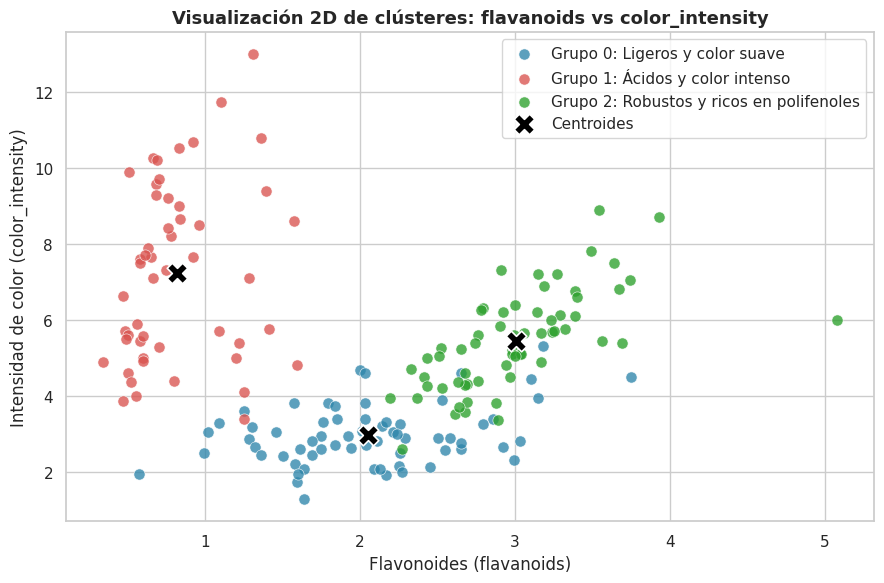

In [5]:
# Selección de dos variables relevantes: flavanoids vs color_intensity
var_x = "flavanoids"
var_y = "color_intensity"

nombres_grupos = {
    0: "Grupo 0: Ligeros y color suave",
    1: "Grupo 1: Ácidos y color intenso",
    2: "Grupo 2: Robustos y ricos en polifenoles"
}
colores = {0: "#2E86AB", 1: "#D9534F", 2: "#2CA02C"}

# Centroides transformados de vuelta a la escala original
centroides_orig = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=columnas_numericas
)

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(df["cluster"].unique()):
    sub = df[df["cluster"] == c]
    ax.scatter(
        sub[var_x], sub[var_y],
        label=nombres_grupos[c],
        color=colores[c],
        alpha=0.78, s=65, edgecolor="white", linewidth=0.5
    )

# Graficar centroides
ax.scatter(
    centroides_orig[var_x], centroides_orig[var_y],
    marker="X", s=220, color="black", edgecolor="white", linewidth=1.2,
    label="Centroides", zorder=6
)

ax.set_title(f"Visualización 2D de clústeres: {var_x} vs {var_y}", fontsize=13, fontweight="bold")
ax.set_xlabel("Flavonoides (flavanoids)")
ax.set_ylabel("Intensidad de color (color_intensity)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


**¿Qué tan buenos parecen los grupos en esta visualización 2D?**

Al graficar `flavanoids` frente a `color_intensity`, la separación visual es bastante buena, especialmente para el Grupo 1 (bajos flavonoides y alta intensidad de color), que queda claramente aislado en la zona superior izquierda. Sin embargo, entre el **Grupo 0** y el Grupo 2 existe una ligera zona de frontera/solapamiento en valores intermedios de flavonoides (`~2.2`–`3.1`) e intensidad de color (`~3.5`–`5.3`). Esto es esperable porque el agrupamiento se calculó utilizando las 13 variables simultáneamente (por ejemplo, `proline` y `alcohol` separan con fuerza al Grupo 2 del Grupo 0, aunque no aparezcan en estos dos ejes).


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Visualiza los grupos en dos componentes mediante PCA, usando la misma matriz preparada para el agrupamiento.
<ul>
  <li>Indica el porcentaje de varianza explicada por los dos componentes y comenta qué información puede perderse en la proyección.</li>
  <li>Evalúa la calidad de los grupos en la matriz preparada, no en la proyección 2D.</li>
</ul>
</div>

Varianza explicada por PC1: 36.20%
Varianza explicada por PC2: 19.21%
Varianza explicada acumulada (PC1 + PC2): 55.41%
Varianza no explicada (perdida en la proyección 2D): 44.59%

Cargas de las variables en los dos primeros componentes:
                                PC1    PC2
alcohol                       0.144  0.484
malic_acid                   -0.245  0.225
ash                          -0.002  0.316
alcalinity_of_ash            -0.239 -0.011
magnesium                     0.142  0.300
total_phenols                 0.395  0.065
flavanoids                    0.423 -0.003
nonflavanoid_phenols         -0.299  0.029
proanthocyanins               0.313  0.039
color_intensity              -0.089  0.530
hue                           0.297 -0.279
od280/od315_of_diluted_wines  0.376 -0.164
proline                       0.287  0.365


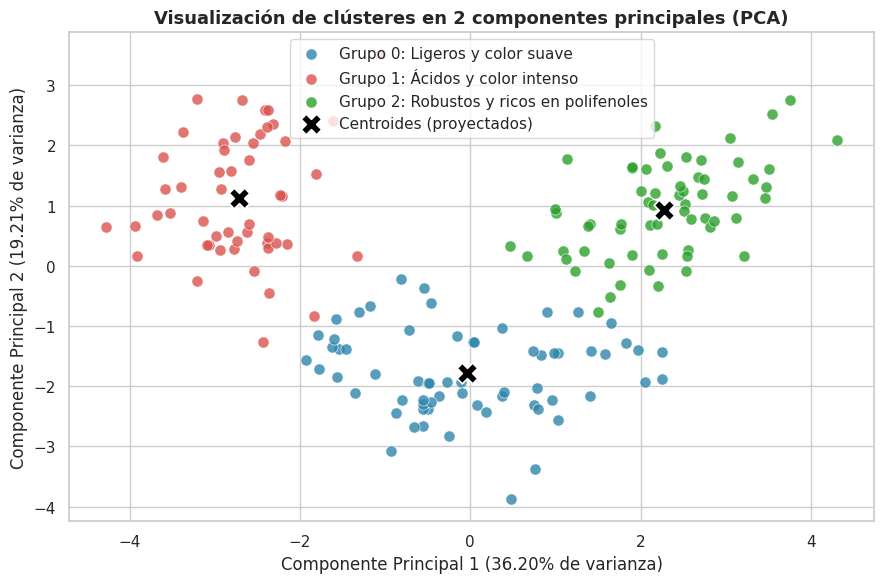

In [6]:
# PCA en 2 componentes usando la misma matriz preparada (X_scaled)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroides_pca = pca.transform(kmeans.cluster_centers_)

var_exp = pca.explained_variance_ratio_ * 100
var_total = var_exp.sum()
var_perdida = 100 - var_total

print(f"Varianza explicada por PC1: {var_exp[0]:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]:.2f}%")
print(f"Varianza explicada acumulada (PC1 + PC2): {var_total:.2f}%")
print(f"Varianza no explicada (perdida en la proyección 2D): {var_perdida:.2f}%")

# Cargas (loadings) de las variables originales en PC1 y PC2
cargas = pd.DataFrame(
    pca.components_.T,
    index=columnas_numericas,
    columns=["PC1", "PC2"]
).round(3)
print("\nCargas de las variables en los dos primeros componentes:")
print(cargas)

# Gráfica de clústeres en el plano PCA
fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(df["cluster"].unique()):
    mask = df["cluster"] == c
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=nombres_grupos[c],
        color=colores[c],
        alpha=0.8, s=65, edgecolor="white", linewidth=0.5
    )

ax.scatter(
    centroides_pca[:, 0], centroides_pca[:, 1],
    marker="X", s=220, color="black", edgecolor="white", linewidth=1.2,
    label="Centroides (proyectados)", zorder=6
)

ax.set_title("Visualización de clústeres en 2 componentes principales (PCA)", fontsize=13, fontweight="bold")
ax.set_xlabel(f"Componente Principal 1 ({var_exp[0]:.2f}% de varianza)")
ax.set_ylabel(f"Componente Principal 2 ({var_exp[1]:.2f}% de varianza)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


### Análisis de la proyección PCA y evaluación en la matriz preparada

* **Varianza explicada y pérdida de información:** Los dos primeros componentes principales explican en conjunto el 55.41% de la varianza total (36.20% en PC1 y 19.21% en PC2). PC1 resume principalmente el contenido polifenólico (`flavanoids`, `total_phenols`, `od280/od315`, `proanthocyanins`), mientras que PC2 captura sobre todo intensidad de color, graduación alcohólica y prolina (`color_intensity`, `alcohol`, `proline`). Por lo tanto, al proyectar de 13 a 2 dimensiones se pierde el 44.59% de la varianza original, concentrada en las componentes PC3 a PC13 (donde residen variaciones relevantes de cenizas `ash`, alcalinidad `alcalinity_of_ash`, magnesio y matices de acidez málica).
* **Evaluación en la matriz preparada (no en la proyección 2D):** Aunque en el plano PCA los tres grupos se observan muy bien diferenciados, la calidad real de la partición debe evaluarse sobre la matriz preparada de 13 dimensiones (`X_scaled`). Una proyección 2D comprime casi la mitad de la variabilidad y puede distorsionar distancias euclidianas reales: dos observaciones alejadas en dimensiones descartadas pueden parecer cercanas en 2D, o viceversa. En el espacio completo preparado (`X_scaled`), la partición logra reducir la inercia en un 44.77% respecto a k = 1 (de `2314.00` a `1277.93`) con tamaños equilibrados y perfiles químicos consistentes, lo cual se verifica cuantitativamente en la siguiente sección mediante el coeficiente de silueta.


---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la silueta de los grupos en la matriz preparada, siempre que haya entre 2 y n-1 grupos para n observaciones. Contrasta su valor con el tamaño y la interpretación de los grupos; compáralo con la partición jerárquica si usaste la misma matriz.
</div>

Coeficiente de silueta de k-Means (k=3) en la matriz preparada: 0.2849

Silueta en la matriz preparada para distintos valores de k:
    Silueta
k          
2    0.2593
3    0.2849
4    0.2602
5    0.2016
6    0.2372
7    0.2036
8    0.1570
9    0.1499
10   0.1436

Resumen de silueta por grupo (k-Means):
         Cantidad   Media  Mínimo  Máximo
cluster                                  
0              65  0.1774 -0.0228  0.3764
1              51  0.3506  0.0611  0.4908
2              62  0.3434  0.0352  0.4977

Coeficiente de silueta de Agrupamiento Jerárquico (Ward, k=3): 0.2774
Índice de Rand Ajustado (ARI) entre k-Means y Jerárquico (Ward): 0.8530

Tabla de contingencia (k-Means vs Jerárquico Ward):
Jerárquico (Ward)   0   1   2
k-Means                      
0                  57   5   3
1                   0  51   0
2                   1   0  61


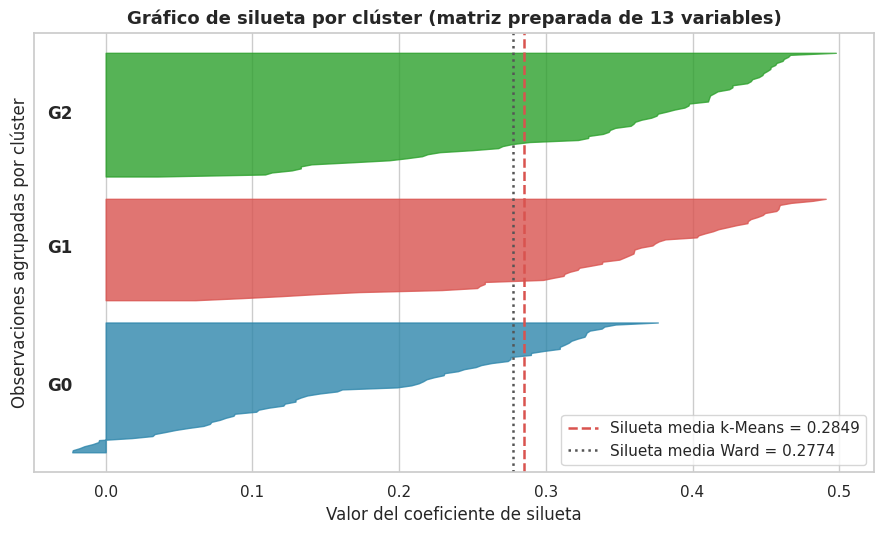

In [7]:
# Verificación de la condición 2 <= k <= n - 1
n_obs = X_scaled.shape[0]
assert 2 <= k_optimo <= n_obs - 1, "El número de grupos debe estar entre 2 y n - 1."

# Coeficiente de silueta global para k = 3 en la matriz preparada X_scaled
sil_kmeans = silhouette_score(X_scaled, df["cluster"])
print(f"Coeficiente de silueta de k-Means (k={k_optimo}) en la matriz preparada: {sil_kmeans:.4f}")

# Silueta para k = 2..10 para contextualizar la elección de k = 3
sil_por_k = {}
for k in range(2, min(10, n_obs - 1) + 1):
    etiquetas_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    sil_por_k[k] = round(silhouette_score(X_scaled, etiquetas_k), 4)
print("\nSilueta en la matriz preparada para distintos valores de k:")
print(pd.Series(sil_por_k, name="Silueta").rename_axis("k").to_frame())

# Silueta desglosada por clúster
sil_muestras = silhouette_samples(X_scaled, df["cluster"])
df["silueta"] = sil_muestras
resumen_sil = df.groupby("cluster")["silueta"].agg(
    Cantidad="count",
    Media="mean",
    Mínimo="min",
    Máximo="max"
).round(4)
print("\nResumen de silueta por grupo (k-Means):")
print(resumen_sil)

# Comparación con agrupamiento jerárquico (enlace Ward, k = 3) en la misma matriz preparada
jerarquico = AgglomerativeClustering(n_clusters=k_optimo, linkage="ward")
etiquetas_ward = jerarquico.fit_predict(X_scaled)
sil_ward = silhouette_score(X_scaled, etiquetas_ward)
ari = adjusted_rand_score(df["cluster"], etiquetas_ward)

print(f"\nCoeficiente de silueta de Agrupamiento Jerárquico (Ward, k={k_optimo}): {sil_ward:.4f}")
print(f"Índice de Rand Ajustado (ARI) entre k-Means y Jerárquico (Ward): {ari:.4f}")
print("\nTabla de contingencia (k-Means vs Jerárquico Ward):")
print(pd.crosstab(df["cluster"], etiquetas_ward, rownames=["k-Means"], colnames=["Jerárquico (Ward)"]))

# Gráfico de silueta por clúster
fig, ax = plt.subplots(figsize=(9, 5.5))
y_lower = 10
for c in sorted(df["cluster"].unique()):
    vals = np.sort(sil_muestras[df["cluster"] == c])
    size_c = vals.shape[0]
    y_upper = y_lower + size_c
    ax.fill_betweenx(
        np.arange(y_lower, y_upper), 0, vals,
        facecolor=colores[c], edgecolor=colores[c], alpha=0.8
    )
    ax.text(-0.04, y_lower + 0.5 * size_c, f"G{c}", fontweight="bold", va="center")
    y_lower = y_upper + 10

ax.axvline(x=sil_kmeans, color="#D9534F", linestyle="--", linewidth=1.8, label=f"Silueta media k-Means = {sil_kmeans:.4f}")
ax.axvline(x=sil_ward, color="#555555", linestyle=":", linewidth=1.8, label=f"Silueta media Ward = {sil_ward:.4f}")
ax.set_title("Gráfico de silueta por clúster (matriz preparada de 13 variables)", fontsize=13, fontweight="bold")
ax.set_xlabel("Valor del coeficiente de silueta")
ax.set_ylabel("Observaciones agrupadas por clúster")
ax.set_yticks([])
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Interpretación del coeficiente de silueta y comparación con agrupamiento jerárquico

* **Valor global en la matriz preparada:** k-Means con k = 3 alcanza una silueta promedio de 0.2849 en el espacio estandarizado de 13 dimensiones, que además corresponde al máximo global entre todos los valores evaluados (k = 2 a k = 10). Por lo queuna silueta cercana a `0.29` refleja una estructura de grupos real y moderadamente bien separada.
* **Contraste con el tamaño y la interpretación de los grupos:** Los tres grupos están bien balanceados, sin clústeres diminutos ni atípicos aislados. Al desglosar la silueta por grupo:
  * **Grupo 1 (*Ácidos y color intenso*, 51 vinos):** silueta media de 0.3506 (todos sus valores son positivos, entre `0.0611` y `0.4908`), confirmando que es el grupo más cohesivo y mejor diferenciado.
  * **Grupo 2 (*Robustos y ricos en polifenoles*, 62 vinos):** silueta media de 0.343 (también completamente positiva, entre `0.0352` y `0.4977`), muy bien definido.
  * **Grupo 0 (*Ligeros y color suave*, 65 vinos):** silueta media más baja (0.1774, con mínimo ligeramente negativo de `-0.0228`), lo que refleja mayor variabilidad interna y unas pocas observaciones ubicadas cerca de la frontera con los otros dos grupos.
* **Comparación con la partición jerárquica (Ward, k = 3) en la misma matriz:** Al aplicar agrupamiento jerárquico con enlace Ward sobre exactamente la misma matriz `X_scaled`, la silueta obtenida es 0.2774, ligeramente inferior a la de k-Means (0.2849). Además, la tabla de contingencia y el Índice de Rand Ajustado (ARI = 0.8530) muestran que 169 de los 178 vinos (94.9%) son agrupados de manera coincidente por ambos algoritmos (el Grupo 1 coincide al 100% y el Grupo 2 en 61 de 62 casos; las pocas diferencias ocurren en 8 observaciones fronterizas del Grupo 0). Esto confirma que la estructura de tres perfiles enológicos es sólida y consistente entre ambos métodos, con una leve ventaja de cohesión para k-Means.
